# Divar Real-Estate Dataset — Preprocessing

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">در این نوت‌بوک داده‌ی خام را برای بخش آمار و مدل‌سازی آماده می‌کنیم. در هر مرحله اول نگاهی به داده می‌اندازیم، بعد تغییر را اعمال می‌کنیم و در آخر نتیجه را چک می‌کنیم.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">چند قراری که در کل نوت‌بوک رعایت کرده‌ایم:</p>
<ul dir="rtl" style="direction:rtl; text-align:right; padding-right:2.4em; padding-left:0;">
<li dir="rtl" style="text-align:right;">در تمیزکاری هیچ ردیفی حذف نمی‌شود. مقدارهای غیرممکن NA می‌شوند و ردیف‌های مشکوک flag می‌شوند؛ اینکه چه ردیف‌هایی کنار گذاشته شوند را هر تحلیل خودش تصمیم می‌گیرد.</li>
<li dir="rtl" style="text-align:right;">هر threshold همان جایی تعیین شده که خروجیِ پشتیبانش دیده می‌شود. فهرست همه‌ی این انتخاب‌ها در انتهای نوت‌بوک آمده است.</li>
<li dir="rtl" style="text-align:right;">سلول‌ها ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">df</code>⁩ را مستقیم تغییر می‌دهند، پس نوت‌بوک را باید از اول تا آخر اجرا کرد (Run All).</li>
</ul>
</div>

In [ ]:
import re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import jdatetime
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 90, "axes.titleweight": "bold"})
pd.set_option("display.width", 200, "display.max_columns", 30)

DATA_PATH, CITY_PATH = "Divar.csv", "iran_city_classification.csv"
FA_DIGITS = str.maketrans("۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩", "01234567890123456789")

def check(cols, n=3):
    """After a step: shape, missing values and a few distinct values of the columns it touched."""
    print(df.shape)
    return pd.DataFrame({"missing": df[cols].isna().sum(),
                         "examples": [df[c].dropna().drop_duplicates().head(n).tolist() for c in cols]})

## 1. Load and first look

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">توضیحات و عنوان آگهی‌ها حدود ۷۰۰ MB هستند، برای همین فعلاً کنارشان می‌گذاریم و فقط در بخش ۷ و ۹ سراغشان می‌رویم. ستون‌های متنی کوتاه را هم از همین اول به ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">category</code>⁩ تبدیل می‌کنیم تا حافظه‌ی کمتری بگیرند؛ مقدارها عوض نمی‌شوند.</p>
</div>

In [ ]:
t0 = time.time()
raw = pd.read_csv("../data/Divar.csv", usecols=lambda c: c not in ("Unnamed: 0", "description", "title"), low_memory=False)
for c in raw.columns:  # text -> category: same values, 1 GB -> 0.2 GB
    if pd.api.types.is_string_dtype(raw[c]):
        raw[c] = raw[c].astype("category")
print(f"{raw.shape} | {raw.memory_usage(deep=True).sum() / 1e9:.2f} GB | {time.time() - t0:.0f} s")
raw.head(3)

(1000000, 58) | 0.69 GB | 15 s


,cat2_slug,cat3_slug,city_slug,neighborhood_slug,created_at_month,user_type,rent_mode,rent_value,rent_to_single,rent_type,price_mode,price_value,credit_mode,credit_value,rent_credit_transform,...,building_direction,has_pool,has_jacuzzi,has_sauna,floor_material,property_type,regular_person_capacity,extra_person_capacity,cost_per_extra_person,rent_price_on_regular_days,rent_price_on_special_days,rent_price_at_weekends,location_latitude,location_longitude,location_radius
0,temporary-rent,villa,karaj,mehrshahr,2024-08-01 00:00:00,مشاور املاک,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,4.0,6,350000.0,1500000.0,3.500000e+09,3500000.0,35.811684,50.936600,500.0
1,residential-sell,apartment-sell,tehran,gholhak,2024-05-01 00:00:00,مشاور املاک,NaN,NaN,NaN,NaN,مقطوع,8.500000e+09,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,500.0
2,residential-rent,apartment-rent,tehran,tohid,2024-10-01 00:00:00,NaN,مقطوع,26000000.0,NaN,NaN,NaN,NaN,مقطوع,750000000.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.703865,51.373459,NaN


In [ ]:
fill = raw.notna().mean().sort_values()
fill.head(6).round(5)

rent_to_single                0.00002
cost_per_extra_person         0.01024
rent_price_on_special_days    0.01046
rent_price_at_weekends        0.01355
rent_price_on_regular_days    0.01807
extra_person_capacity         0.02401
dtype: float64

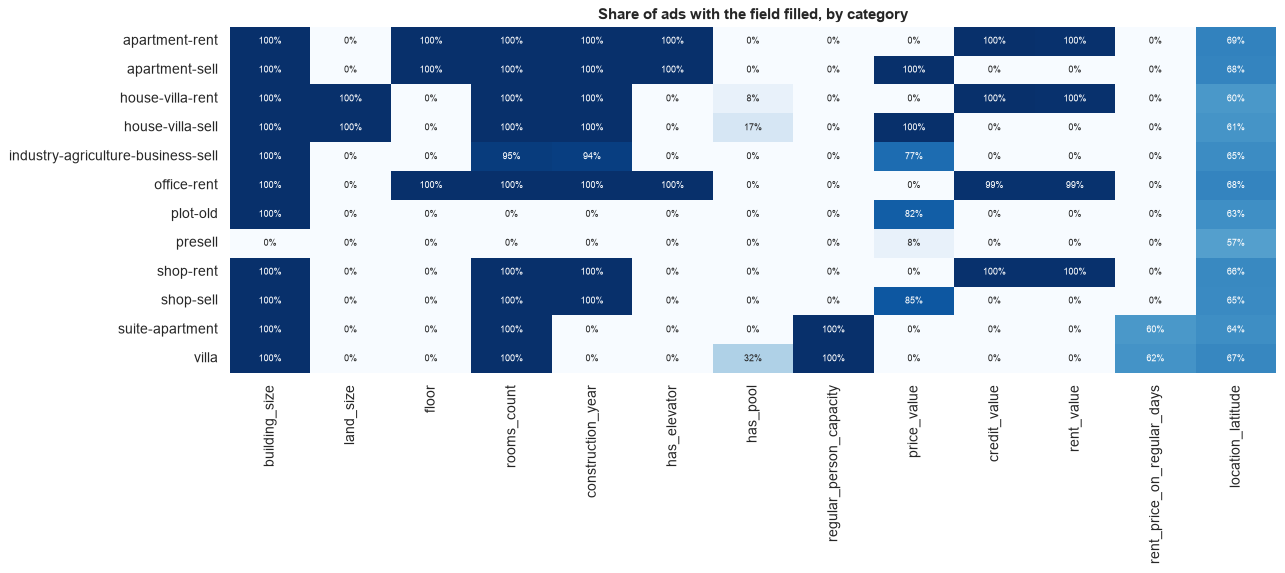

In [ ]:
cols = ["building_size", "land_size", "floor", "rooms_count", "construction_year", "has_elevator", "has_pool",
        "regular_person_capacity", "price_value", "credit_value", "rent_value", "rent_price_on_regular_days",
        "location_latitude"]
top = raw["cat3_slug"].value_counts().index[:12]
share = raw[raw["cat3_slug"].isin(top)].groupby("cat3_slug", observed=True)[cols].agg(lambda s: s.notna().mean())
plt.figure(figsize=(15, 5))
sns.heatmap(share, cmap="Blues", annot=True, fmt=".0%", cbar=False, annot_kws={"size": 7})
plt.title("Share of ads with the field filled, by category"); plt.xlabel(""); plt.ylabel(""); plt.show()

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">از نقشه‌ی بالا معلوم است که بیشتر جاهای خالی ساختاری‌اند و هر دسته فرم خودش را دارد: آسانسور فقط برای آپارتمان و دفتر پرسیده می‌شود، استخر فقط برای ویلا و ظرفیت نفرات فقط برای اجاره‌ی شبانه. پس NA در این ستون‌ها بیشتر یعنی «این سؤال پرسیده نشده» و پر کردنشان با یک مقدار سراسری درست نیست.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">دو نکته‌ی دیگر: در ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">plot-old</code>⁩ ستون ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">land_size</code>⁩ خالی است که در بخش ۳ به آن برمی‌گردیم، و ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">rent_to_single</code>⁩ فقط در ۱۹ آگهی پر شده که حذفش می‌کنیم.</p>
</div>

In [ ]:
df = raw.drop(columns=fill[fill < 0.001].index)
print("dropped (filled in < 0.1% of ads):", fill[fill < 0.001].index.tolist(), "|", df.shape)

dropped (filled in < 0.1% of ads): ['rent_to_single'] | (1000000, 57)


## 2. Types and form tokens

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">وقتی کاربر field‌ای را باز می‌کند و چیزی انتخاب نمی‌کند، فرم دیوار مقدار ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">unselect</code>⁩ ثبت می‌کند. این تنها مقدار جای‌خالی بود که در داده پیدا کردیم:</p>
</div>

In [ ]:
unselect = {c: raw[c].astype("string").str.strip().eq("unselect").sum() for c in raw.select_dtypes("category")}
pd.Series(unselect).loc[lambda s: s > 0].sort_values(ascending=False)

has_cooling_system         5917
building_direction         3207
has_heating_system         3118
floor_material             1667
has_warm_water_provider    1382
has_restroom                628
deed_type                   569
unit_per_floor              246
has_balcony                 223
total_floors_count          125
dtype: int64

In [ ]:
for c in df.columns:
    if df[c].dtype.kind not in "biufc":
        s = df[c].astype("string").str.strip()
        df[c] = s.mask(s.str.lower().eq("unselect"))
check(["has_balcony", "deed_type", "floor_material"])

(1000000, 57)


,missing,examples
has_balcony,493812,"[true, false, True]"
deed_type,747111,"[single_page, other, written_agreement]"
floor_material,595683,"[ceramic, carpet, wood_parquet]"


<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">در پنج ستون عددی مقدارهایی مثل ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">30+</code>⁩ و ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">more_than_8</code>⁩ هم هست. ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">30+</code>⁩ یعنی «۳۰ یا بیشتر»، پس عدد را نگه می‌داریم ولی با ستون ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">_is_capped</code>⁩ مشخص می‌کنیم که به سقف فرم خورده است.</p>
</div>

In [ ]:
INT_COLS = ["floor", "total_floors_count", "unit_per_floor", "extra_person_capacity", "regular_person_capacity"]
{c: df[c].dropna().astype("string").loc[lambda s: ~s.str.fullmatch(r"\d+")].value_counts().head(4).to_dict() for c in INT_COLS}

{'floor': {'-1': 4462, '30+': 675, '2.0': 86, '1.0': 70},
 'total_floors_count': {'30+': 233, '4.0': 55, '3.0': 43, '5.0': 40},
 'unit_per_floor': {'more_than_8': 2083},
 'extra_person_capacity': {'30+': 724, '5.0': 4, '4.0': 3, '2.0': 3},
 'regular_person_capacity': {'4.0': 7496,
  '2.0': 5219,
  '6.0': 3228,
  '5.0': 2936}}

In [ ]:
def parse_int_like(s):
    """'3' / '3.0' / '30+' / 'more_than_8' -> integer, plus a flag for the open-ended form buckets."""
    t = s.astype("string").str.translate(FA_DIGITS).str.strip()
    num = t.str.extract(r"^\s*(?:more_than_)?(\d+)\s*\+?\s*$", expand=False).fillna(t)
    capped = t.str.contains(r"\+|more_than", regex=True, na=False).astype("boolean")
    return pd.to_numeric(num, errors="coerce").round().astype("Int32"), capped

test = pd.Series(["3", "3.0", "30+", "more_than_8", "-1", "۵", None])
value, capped = parse_int_like(test)
pd.DataFrame({"input": test, "value": value, "capped": capped})

,input,value,capped
0,3,3,False
1,3.0,3,False
2,30+,30,True
3,more_than_8,8,True
4,-1,-1,False
5,۵,5,False
6,NaN,<NA>,False


In [ ]:
for c in INT_COLS:
    df[c], capped = parse_int_like(df[c])
    if capped.any():
        df[f"{c}_is_capped"] = capped
check(INT_COLS)

(1000000, 61)


,missing,examples
floor,458252,"[3, 4, 2]"
total_floors_count,695773,"[6, 3, 14]"
unit_per_floor,697963,"[2, 4, 1]"
extra_person_capacity,975991,"[6, 7, 2]"
regular_person_capacity,970130,"[4, 8, 5]"


<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">ستون‌های بله/خیر را از روی مقدارشان پیدا می‌کنیم، نه از روی اسم. ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">has_balcony</code>⁩ به صورت متن ذخیره شده و بقیه‌ی ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">has_*</code>⁩ها بولی‌اند. چند ستون ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">has_*</code>⁩ هم در واقع نوع امکانات را نگه می‌دارند (مثل نوع گرمایش) و باید دست‌نخورده بمانند.</p>
</div>

In [ ]:
BOOL_MAP = {"true": True, "1": True, "yes": True, "false": False, "0": False, "no": False}

def to_bool(s):
    """true/false text in any case -> nullable boolean; NA stays NA."""
    return s.astype("string").str.lower().map(BOOL_MAP).astype("boolean")

print(to_bool(pd.Series(["True", "false", "1", "No", None])).tolist())
bool_like = [c for c in df if df[c].dtype == bool or (df[c].dtype.kind == "O" and df[c].notna().any()
             and set(df[c].dropna().str.lower().unique()) <= BOOL_MAP.keys())]
print(len(bool_like), "true/false columns | left alone because they hold categories:",
      [c for c in df.filter(like="has_") if c not in bool_like])

[True, False, True, False, <NA>]
16 true/false columns | left alone because they hold categories: ['has_warm_water_provider', 'has_heating_system', 'has_cooling_system', 'has_restroom']


In [ ]:
for c in bool_like:
    df[c] = to_bool(df[c])
check(["has_balcony", "has_elevator", "has_pool"])

(1000000, 61)


,missing,examples
has_balcony,493812,"[True, False]"
has_elevator,458251,"[True, False]"
has_pool,970610,"[False, True]"


<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">سال ساخت شمسی است و قدیمی‌ترین گزینه‌ی فرم «قبل از ۱۳۷۰» است. این را ۱۳۶۹ می‌گذاریم و flag می‌کنیم، پس هر میانگین سنی که از این ستون دربیاید در واقع lower bound است. تعداد اتاق را هم به عدد تبدیل می‌کنیم.</p>
</div>

In [ ]:
df["construction_year"].dropna().loc[lambda s: ~s.str.translate(FA_DIGITS).str.fullmatch(r"\d{4}")].value_counts()

construction_year
قبل از ۱۳۷۰    20637
Name: count, dtype: Int64

In [ ]:
year_txt = df["construction_year"].astype("string").str.strip()
censored = year_txt.eq("قبل از ۱۳۷۰").fillna(False)
year = pd.to_numeric(year_txt.str.translate(FA_DIGITS), errors="coerce").where(~censored, 1369)
df["construction_year"] = year.where(year.between(1300, 1404)).astype("Int32")
df["construction_year_is_censored"] = censored.astype("boolean")
df["building_age"] = (1403 - df["construction_year"]).astype("Int32")  # the data is a 1403 snapshot

ROOMS = {"بدون اتاق": 0, "یک": 1, "دو": 2, "سه": 3, "چهار": 4, "پنج یا بیشتر": 5}
print(df["rooms_count"].value_counts().to_dict())
df["rooms"] = df["rooms_count"].map(ROOMS).astype("Int8")
df["rooms_is_capped"] = df["rooms_count"].eq("پنج یا بیشتر").fillna(False).astype("boolean")
check(["construction_year", "building_age", "rooms"])

{'دو': 404050, 'یک': 192083, 'سه': 138633, 'بدون اتاق': 75898, 'چهار': 21371, 'پنج یا بیشتر': 13864}
(1000000, 65)


,missing,examples
construction_year,184172,"[1384, 1401, 1400]"
building_age,184172,"[19, 2, 3]"
rooms,154101,"[3, 1, 2]"


<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">ستون تاریخ فقط ماه میلادی را دارد و هر ماه میلادی دو ماه شمسی را پوشش می‌دهد. label شمسی را ماهی گذاشتیم که روز ۱۵ آن ماه میلادی در آن است، یعنی ماهی که بیشتر روزها (۶۳ تا ۷۰ درصد) در آن افتاده‌اند.</p>
</div>

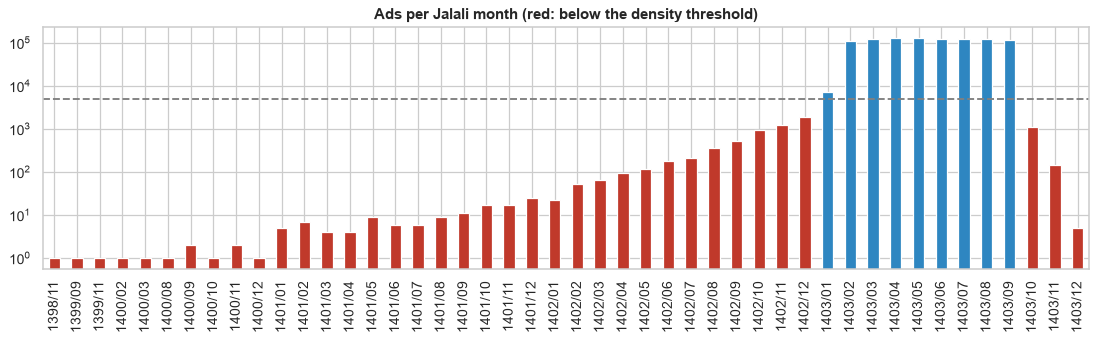

{np.int16(1398): 1, np.int16(1399): 2, np.int16(1400): 9, np.int16(1401): 120, np.int16(1402): 5664, np.int16(1403): 994204}


In [ ]:
month = pd.to_datetime(df["created_at_month"], errors="coerce")
jalali = {ts: jdatetime.date.fromgregorian(date=(ts + pd.Timedelta(days=14)).date()) for ts in month.dropna().unique()}
label = month.map({ts: f"{j.year}/{j.month:02d}" for ts, j in jalali.items()}).astype("string")
df["created_at_month"] = month
df["created_year_g"], df["created_month_g"] = month.dt.year.astype("Int16"), month.dt.month.astype("Int8")
df["created_month_fa"] = pd.Categorical(label, categories=sorted(label.dropna().unique()), ordered=True)
df["created_year_fa"] = pd.to_numeric(label.str[:4], errors="coerce").astype("Int16")
df["created_month_fa_num"] = pd.to_numeric(label.str[5:], errors="coerce").astype("Int8")

DENSE_MIN = 5_000
counts = df["created_month_fa"].value_counts().sort_index()
ax = counts.plot.bar(figsize=(15, 3.5), logy=True, color=np.where(counts >= DENSE_MIN, "#2e86c1", "#c0392b"))
ax.axhline(DENSE_MIN, ls="--", color="grey"); ax.set(title="Ads per Jalali month (red: below the density threshold)", xlabel="")
plt.show()
print(df.groupby("created_year_fa")["created_month_fa"].size().to_dict())

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">تقریباً همه‌ی داده (۹۹.۴٪) مربوط به ۱۴۰۳ است. از ۱۴۰۰ فقط ۹ آگهی داریم و از ۱۴۰۲ حدود ۵٬۷۰۰. پس مقایسه‌ی ۱۴۰۰ تا ۱۴۰۳ که سؤال ۷ خواسته با این داده ممکن نیست.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">ماه‌های قرمز لبه‌های بازه‌ی جمع‌آوری داده‌اند. threshold ۵٬۰۰۰ آگهی را برای جدا کردنشان گذاشتیم؛ فاصله‌ی این ماه‌ها با ۹ ماه اصلی (۱۴۰۳/۰۱ تا ۱۴۰۳/۰۹) آن‌قدر زیاد است که عدد دقیق threshold فرقی در نتیجه نمی‌کند.</p>
</div>

In [ ]:
FAMILY = {"residential-sell": "sell", "commercial-sell": "sell", "residential-rent": "long_rent",
          "commercial-rent": "long_rent", "temporary-rent": "temp_rent", "real-estate-services": "service"}
df["deal_family"] = df["cat2_slug"].map(FAMILY).astype("category")
for c in df.columns:  # remaining text -> category (memory)
    if df[c].dtype in ("object", "string") and df[c].nunique() <= 5000:
        df[c] = df[c].astype("category")
print(df["deal_family"].value_counts(dropna=False).to_dict(), f"| {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

{'sell': 597569, 'long_rent': 353125, 'temp_rent': 29903, 'service': 19403} | 0.25 GB


## 3. Area

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">متراژ را قبل از قیمت تمیز می‌کنیم، چون در بخش ۴ از قیمت هر متر برای پیدا کردن خطای واحد استفاده می‌شود و یک متراژ اشتباه مثل ۱۱۱۱۱ می‌تواند خطای ساختگی بسازد. اول توزیع متراژ هر دسته:</p>
</div>

In [ ]:
by_cat = df.groupby("cat3_slug", observed=True)
area_q = by_cat["building_size"].quantile([.01, .5, .99]).unstack().rename(columns=lambda q: f"p{q * 100:02.0f}")
area_q.insert(0, "land_size filled", by_cat["land_size"].agg(lambda s: s.notna().mean()))
area_q.round(2)

,land_size filled,p01,p50,p99
cat3_slug,,,,
apartment-rent,0.0,40.00,95.0,300.0
apartment-sell,0.0,40.00,90.0,290.0
house-villa-rent,1.0,20.00,100.0,10000.0
house-villa-sell,1.0,8.00,130.0,1200.0
industry-agriculture-business-rent,0.0,12.00,500.0,1230500.0
industry-agriculture-business-sell,0.0,25.00,1650.0,1300000.0
office-rent,0.0,8.00,90.0,1500.0
office-sell,0.0,13.54,85.0,2513.8
partnership,0.0,200.00,200.0,200.0


<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">از این جدول دو چیز معلوم می‌شود. اول اینکه در ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">plot-old</code>⁩ ستون ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">land_size</code>⁩ اصلاً پر نشده و متراژ زمین داخل ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">building_size</code>⁩ رفته است. پس دو ستون می‌سازیم: ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">area</code>⁩ که قیمت آگهی بر اساس آن است و ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">land_area</code>⁩ که متراژ زمین است.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">دوم اینکه یک بازه برای همه جواب نمی‌دهد: ۴۰ متر برای آپارتمان عادی است ولی برای زمین کشاورزی نه. برای هر دسته بازه‌ی جدا گذاشتیم. جایی که percentileها سالم‌اند (مثل آپارتمان) بازه را خیلی بازتر از آن‌ها گرفتیم، و جایی که خود p99 خراب است (ویلا ۶۸۰ هزار متر، سوئیت ۱۱٬۱۱۱ متر) سقف را از اندازه‌ای گرفتیم که آن نوع ملک واقعاً می‌تواند داشته باشد. هدف فقط حذف مقدارهای غیرممکن است، نه outlierها.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">عددهایی مثل ۱۱۱۱۱ یا ۹۹۹۹۹۹ معمولاً وقتی وارد می‌شوند که کاربر فقط می‌خواهد field را پر کند. تابع زیر این‌ها را پیدا می‌کند و برای مبلغ‌ها هم از آن استفاده می‌کنیم:</p>
</div>

In [ ]:
def is_repdigit(s, min_digits=3):
    """111111, 9999999, 22220000 ...: one digit repeated (trailing zeros ignored) = keyboard noise."""
    v = s.astype("float64")
    def one(x):
        d = str(int(x)).rstrip("0")
        return len(d) >= min_digits and len(set(d)) == 1
    return v.map({x: one(x) for x in v[v > 0].unique() if np.isfinite(x)}).fillna(False).astype(bool)

is_repdigit(pd.Series([111_111, 9_999_999, 22_220_000, 1e14, 1_200_000, 250, 0, np.nan])).tolist()

[True, True, True, False, False, False, False, False]

In [ ]:
AREA_BOUNDS = {  # (min, max) m² per cat3; wide around clean percentiles, physical cap where p99 is polluted
    "apartment-rent": (15, 2_000), "apartment-sell": (15, 2_000), "presell": (15, 2_000),
    "house-villa-rent": (15, 5_000), "house-villa-sell": (15, 10_000), "villa": (20, 5_000),
    "office-rent": (8, 5_000), "office-sell": (8, 5_000), "shop-rent": (4, 5_000), "shop-sell": (4, 5_000),
    "workspace": (4, 5_000), "suite-apartment": (10, 1_000), "partnership": (15, 100_000),
    "industry-agriculture-business-rent": (10, 5_000_000), "industry-agriculture-business-sell": (10, 5_000_000),
    "plot-old": (20, 5_000_000)}

assert "area" not in df, "run the notebook from the top"
land_only = df["cat3_slug"].eq("plot-old").fillna(False).astype(bool)  # this form stores the plot in building_size
df["land_area"] = df["land_size"].astype("float64").mask(land_only, df["building_size"])
df["area"] = df["building_size"].astype("float64").mask(land_only, df["land_area"])
df["area_is_land"] = land_only

cat = df["cat3_slug"].astype("string")
low = cat.map({k: v[0] for k, v in AREA_BOUNDS.items()}).fillna(5).astype("float64")
high = cat.map({k: v[1] for k, v in AREA_BOUNDS.items()}).fillna(1_000_000).astype("float64")
for c in ["area", "land_area"]:
    bad = is_repdigit(df[c]) | df[c].ge(10_000_000) | (df[c].notna() & ~df[c].between(low, high))
    df[f"{c}_is_invalid"], df[c] = bad, df[c].mask(bad)
print("invalid:", {c: int(df[f"{c}_is_invalid"].sum()) for c in ["area", "land_area"]})
check(["area", "land_area"])

invalid: {'area': 9549, 'land_area': 3366}
(1000000, 76)


,missing,examples
area,29155,"[500.0, 60.0, 132.0]"
land_area,683412,"[500.0, 700.0, 216.0]"


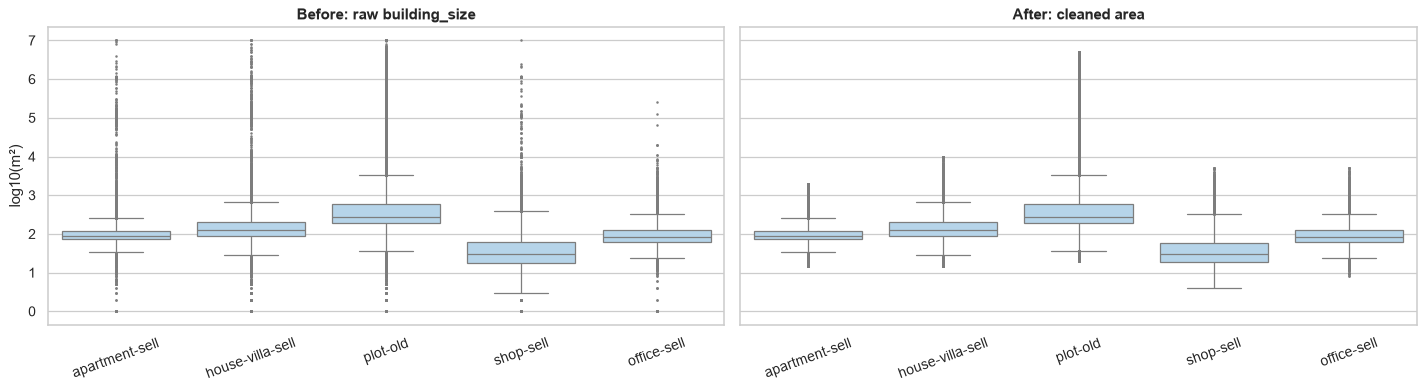

In [ ]:
cats = ["apartment-sell", "house-villa-sell", "plot-old", "shop-sell", "office-sell"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, frame, col, title in [(axes[0], raw, "building_size", "Before: raw building_size"),
                              (axes[1], df, "area", "After: cleaned area")]:
    sub = frame[frame["cat3_slug"].isin(cats) & frame[col].gt(0)]
    sns.boxplot(x=sub["cat3_slug"].astype(str), y=np.log10(sub[col]), order=cats, ax=ax, fliersize=1, color="#aed6f1")
    ax.set(title=title, xlabel="", ylabel="log10(m²)"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">حدود ۹٬۵۰۰ متراژ و ۳٬۴۰۰ متراژ زمین نامعتبر بودند، یعنی حدود ۱٪. در نمودار، مقدارهای خیلی بزرگ ویلا و مغازه رفته‌اند ولی خود جعبه‌ها تقریباً تکان نخورده‌اند. در test تابع هم دیده می‌شود که 1e14 رقم تکراری حساب نمی‌شود؛ این‌طور مقدارها را بازه‌ی مبلغ در بخش بعد می‌گیرد.</p>
</div>

## 4. Prices

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">ستون‌های ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">transformable_*</code>⁩ تقریباً همان ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">credit_value</code>⁩ و ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">rent_value</code>⁩ هستند و حذفشان می‌کنیم. ستون‌های mode هم فقط وضعیت عدد را نشان می‌دهند و تنها چیزی که از آن‌ها لازم داریم «توافقی» و «مجانی» است.</p>
</div>

In [ ]:
assert "transformable_credit" in df, "run the notebook from the top"
print({c: round(float((raw[c] == raw[o]).where(raw[c].notna() | raw[o].notna()).mean()), 4)
       for c, o in [("transformable_credit", "credit_value"), ("transformable_rent", "rent_value")]})
df = df.drop(columns=["transformable_credit", "transformable_rent"])
pd.DataFrame({c: df[c].value_counts() for c in ["price_mode", "credit_mode", "rent_mode"]})

{'transformable_credit': 1.0, 'transformable_rent': 0.9998}


,price_mode,credit_mode,rent_mode
توافقی,5260,899,1672
مجانی,1902,2864,59241
مقطوع,566444,349231,292081


In [ ]:
modes = df[["price_mode", "credit_mode", "rent_mode"]].astype("string")
df["is_negotiable"] = modes.eq("توافقی").any(axis=1).astype(bool)
df["has_free_component"] = modes.eq("مجانی").any(axis=1).astype(bool)
print(df[["is_negotiable", "has_free_component"]].sum().to_dict())
df.loc[df["deal_family"].eq("long_rent"), "rent_value"].value_counts().head(6)

{'is_negotiable': 7062, 'has_free_component': 64007}


rent_value
0.0           59240
100000.0      24733
5000000.0     17474
3000000.0     16873
6000000.0     14490
10000000.0    13760
Name: count, dtype: int64

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">اجاره‌ی ۱۰۰٬۰۰۰ تومان از هر مبلغ دیگری بیشتر تکرار شده، حتی بیشتر از ۵ میلیون. این اجاره‌ی واقعی نیست؛ کسی که رهن کامل می‌دهد و فرم اجاره‌ی صفر قبول نمی‌کند این عدد را می‌نویسد. ۱۱۱٬۱۱۱ هم همین‌طور. هر دو را صفر می‌کنیم و با ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">rent_is_symbolic</code>⁩ علامت می‌زنیم. مبلغ‌های با رقم تکراری را هم قبل از هر محاسبه‌ای NA می‌کنیم.</p>
</div>

In [ ]:
assert "rent_is_symbolic" not in df, "run the notebook from the top"
df["rent_is_symbolic"] = df["rent_value"].isin([100_000, 111_111])
df["rent_value"] = df["rent_value"].mask(df["rent_is_symbolic"], 0.0)

AMOUNT_BOUNDS = {"price_value": (1e7, 1e13), "credit_value": (1e6, 1e12), "rent_value": (1e5, 1e10),
                 "rent_price_on_regular_days": (1e4, 1e10), "rent_price_at_weekends": (1e4, 1e10),
                 "rent_price_on_special_days": (1e4, 1e10)}
for c in AMOUNT_BOUNDS:
    rep = is_repdigit(df[c])
    df[f"{c}_is_placeholder"], df[c] = rep, df[c].astype("float64").mask(rep)
print("symbolic rent:", int(df["rent_is_symbolic"].sum()),
      "| repdigit amounts:", {c: int(df[f"{c}_is_placeholder"].sum()) for c in AMOUNT_BOUNDS})

symbolic rent: 28796 | repdigit amounts: {'price_value': 15902, 'credit_value': 6857, 'rent_value': 5274, 'rent_price_on_regular_days': 428, 'rent_price_at_weekends': 348, 'rent_price_on_special_days': 329}


In [ ]:
lr = df["deal_family"].eq("long_rent")
print("rent_type says full_credit:", int(df["rent_type"].eq("full_credit").sum()),
      "| long-rent ads with zero rent and a credit:", int((lr & df["rent_value"].eq(0) & df["credit_value"].gt(0)).sum()))
fam, credit, rent = df["deal_family"], df["credit_value"], df["rent_value"]
df["contract_type"] = pd.Categorical(np.select(
    [fam.eq("sell"), fam.eq("temp_rent"), lr & rent.eq(0) & credit.gt(0), lr & credit.eq(0) & rent.gt(0),
     lr & credit.gt(0) & rent.gt(0)],
    ["sell", "nightly", "full_credit", "rent_only", "credit_rent"], default=None))
df["contract_type"].value_counts(dropna=False).to_dict()

rent_type says full_credit: 147 | long-rent ads with zero rent and a credit: 85281


{'sell': 597569,
 'credit_rent': 254930,
 'full_credit': 85281,
 'nightly': 29903,
 nan: 29901,
 'rent_only': 2416}

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">قیمتی که برای هر آگهی در نظر می‌گیریم به نوع معامله بستگی دارد: برای فروش ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">price_value</code>⁩، برای اجاره‌ی بلندمدت رهن معادل (⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">credit + rent × 1e6/3e4</code>⁩، همان قیمت تبدیل‌شده‌ای که در داکیومنتیشن پروژه تعریف شده و در داده نبود) و برای اجاره‌ی شبانه قیمت روز عادی. بعد قیمت هر متر هر آگهی را با median آگهی‌های هم‌شهر و هم‌دسته‌اش مقایسه می‌کنیم:</p>
</div>

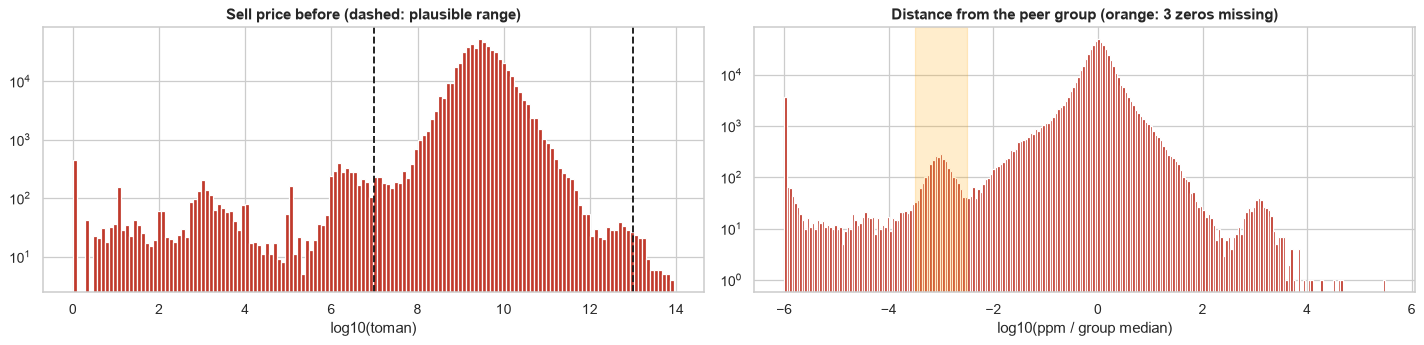

In [ ]:
CREDIT_PER_RENT = 1e6 / 3e4  # 1M toman credit ~ 30k toman monthly rent (project documentation)
MIN_GROUP = 30  # a median of fewer prices is not a reference

def derive_prices(d):
    """equivalent credit -> one target price per deal family -> price per m²."""
    fam = d["deal_family"]
    d["equiv_credit"] = (d["credit_value"] + d["rent_value"] * CREDIT_PER_RENT).where(fam.eq("long_rent"))
    d["target_price"] = (d["price_value"].where(fam.eq("sell"))
                         .fillna(d["equiv_credit"].where(fam.eq("long_rent")))
                         .fillna(d["rent_price_on_regular_days"].where(fam.eq("temp_rent"))))
    d["price_per_sqm"] = d["target_price"] / d["area"]

def peer_log_ratio(d):
    """log10(price per m² / median of the same city x cat3); NA where the group has < MIN_GROUP prices."""
    g = d.groupby([d["city_slug"].astype("string"), d["cat3_slug"].astype("string")], observed=True)["price_per_sqm"]
    ref = g.transform("median").where(g.transform("count") >= MIN_GROUP)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.log10(d["price_per_sqm"] / ref)

derive_prices(df)
before_price = df.loc[df["deal_family"].eq("sell"), "target_price"].copy()
before_ratio = peer_log_ratio(df)[df["deal_family"].eq("sell")].clip(-6, 6)
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].hist(np.log10(before_price[before_price > 0]), bins=150, color="#c0392b")
[axes[0].axvline(np.log10(b), ls="--", color="k") for b in AMOUNT_BOUNDS["price_value"]]
axes[0].set(title="Sell price before (dashed: plausible range)", xlabel="log10(toman)", yscale="log")
axes[1].hist(before_ratio.dropna(), bins=240, color="#c0392b"); axes[1].axvspan(-3.5, -2.5, color="orange", alpha=.2)
axes[1].set(title="Distance from the peer group (orange: 3 zeros missing)", xlabel="log10(ppm / group median)", yscale="log")
plt.tight_layout(); plt.show()

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">در نمودار سمت راست یک برآمدگی جدا حوالی ۳- دیده می‌شود، یعنی قیمت‌هایی که هزار برابر ارزان‌تر از هم‌گروه‌هایشان‌اند. این‌ها آگهی‌هایی‌اند که سه صفر آخر قیمت را جا انداخته‌اند، پس به جای حذف در ۱۰۰۰ ضربشان می‌کنیم. در نمودار چپ هم دو tail غیرواقعی هست (قیمت‌های چند هزار تومانی و تا ۱۰ به توان ۱۴) که با بازه‌ی مبلغ حذف می‌شوند.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">ترتیب این دو کار مهم است. اگر اول بازه را اعمال کنیم، قیمتی که سه صفرش افتاده زیر کف بازه می‌رود و از دست می‌رود. از طرف دیگر هر تصحیح median گروه را کمی جابه‌جا می‌کند و هر حذف روی رهن معادل اثر دارد، پس این مراحل را آن‌قدر تکرار می‌کنیم تا نتیجه دیگر تغییر نکند.</p>
</div>

In [ ]:
UNIT_COLS = ["price_value", "credit_value", "rent_value", "rent_price_on_regular_days", "rent_price_at_weekends",
             "rent_price_on_special_days", "equiv_credit", "target_price", "price_per_sqm"]
assert "price_unit_corrected" not in df, "run the notebook from the top"
corrected, previous = pd.Series(False, index=df.index), None
for outer in range(5):  # correction and range cleaning feed each other
    derive_prices(df)
    for _ in range(5):  # each fix moves the group medians a little
        fix = peer_log_ratio(df).between(-3.5, -2.5)
        if not fix.any():
            break
        for c in UNIT_COLS:
            df[c] = df[c].mask(fix, df[c] * 1000)
        corrected |= fix
    for c, (lo, hi) in AMOUNT_BOUNDS.items():  # after the fix, or recoverable prices die here
        bad = (df[c] > 0) & ~df[c].between(lo, hi)
        if c != "rent_value":  # zero rent = full-credit contract
            bad |= df[c].eq(0)
        df[f"{c}_is_placeholder"] |= bad
        df[c] = df[c].mask(bad)
    current = df["target_price"].fillna(-1).to_numpy()
    if previous is not None and np.array_equal(previous, current):
        break
    previous = current
derive_prices(df)
df["price_unit_corrected"] = corrected
df["price_log_ratio"] = peer_log_ratio(df)
df["price_is_outlier"] = df["price_log_ratio"].abs().gt(1.3).fillna(False)  # 10^1.3 ~ 20x the group median
print(f"passes: {outer + 1} | corrected: {int(corrected.sum()):,} | outliers: {int(df['price_is_outlier'].sum()):,} "
      f"| corrected rows still outlier: {df.loc[corrected, 'price_is_outlier'].mean():.1%}")
check(["target_price", "equiv_credit", "price_per_sqm"])

passes: 4 | corrected: 4,502 | outliers: 10,358 | corrected rows still outlier: 0.0%
(1000000, 90)


,missing,examples
target_price,97810,"[1500000.0, 8500000000.0, 1616666666.6666667]"
equiv_credit,659995,"[1616666666.6666667, 4116666666.666667, 450000..."
price_per_sqm,104735,"[3000.0, 141666666.66666666, 12247474.747474749]"


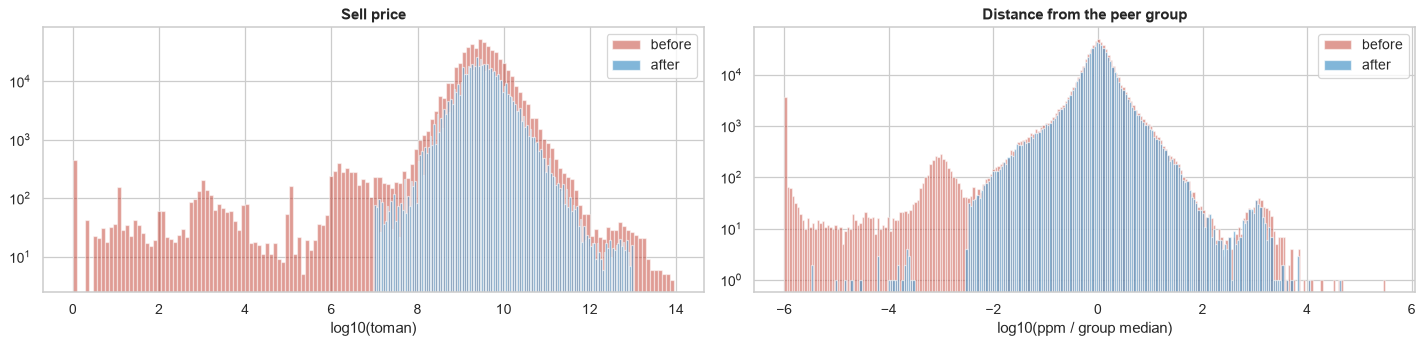

,city,cat3,area,raw price,corrected
93,isfahan,apartment-sell,82.0,2730000.0,2.730000e+09
242,tabriz,apartment-sell,75.0,1111112.0,1.111112e+09
470,tehran,apartment-sell,57.0,4000000.0,4.000000e+09
554,sanandaj,apartment-sell,90.0,2750000.0,2.750000e+09
850,saveh,apartment-sell,88.0,1480000.0,1.480000e+09


In [ ]:
sell = df["deal_family"].eq("sell")
after_price, after_ratio = df.loc[sell, "target_price"], df.loc[sell, "price_log_ratio"].clip(-6, 6)
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].hist(np.log10(before_price[before_price > 0]), bins=150, alpha=.5, color="#c0392b", label="before")
axes[0].hist(np.log10(after_price.dropna()), bins=150, alpha=.6, color="#2e86c1", label="after")
axes[0].set(title="Sell price", xlabel="log10(toman)", yscale="log"); axes[0].legend()
axes[1].hist(before_ratio.dropna(), bins=240, alpha=.5, color="#c0392b", label="before")
axes[1].hist(after_ratio.dropna(), bins=240, alpha=.6, color="#2e86c1", label="after")
axes[1].set(title="Distance from the peer group", xlabel="log10(ppm / group median)", yscale="log"); axes[1].legend()
plt.tight_layout(); plt.show()
m = df["price_unit_corrected"] & sell
pd.DataFrame({"city": df.loc[m, "city_slug"], "cat3": df.loc[m, "cat3_slug"], "area": df.loc[m, "area"],
              "raw price": raw.loc[m, "price_value"], "corrected": df.loc[m, "target_price"]}).head(5)

In [ ]:
flags = [c for c in df if c.endswith(("_is_placeholder", "_is_symbolic", "_unit_corrected", "_is_outlier"))]
df.groupby("deal_family", observed=True)[flags].sum().T.loc[lambda t: t.sum(axis=1) > 0]

deal_family,long_rent,sell,service,temp_rent
rent_is_symbolic,28795,0,0,1
price_value_is_placeholder,15,21552,41,5
credit_value_is_placeholder,9796,0,0,1
rent_value_is_placeholder,5433,0,0,0
rent_price_on_regular_days_is_placeholder,0,0,0,1422
rent_price_at_weekends_is_placeholder,0,0,0,1160
rent_price_on_special_days_is_placeholder,0,0,0,1033
price_unit_corrected,577,2772,0,1153
price_is_outlier,1967,8246,0,145


<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">۴٬۵۰۲ قیمت در ۱۰۰۰ ضرب شدند و بعد از تصحیح هیچ‌کدام outlier نیستند؛ یعنی دقیقاً وسط گروه خودشان نشسته‌اند. اگر فرض «سه صفر جاافتاده» اشتباه بود، این عدد صفر نمی‌شد. حلقه بعد از ۴ دور ثابت شد.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">آگهی‌هایی که قیمت هر مترشان بیش از ۲۰ برابر با median گروه فاصله دارد (حدود ۱۰ هزار ردیف) فقط flag شده‌اند.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">rent_type</code>⁩ هم به کار نمی‌آمد: فقط ۱۴۷ آگهی «رهن کامل» زده‌اند در حالی که ۸۵ هزار آگهی اجاره‌ی صفر دارند. برای همین نوع قرارداد را از خود مبلغ‌ها ساختیم.</p>
</div>

## 5. Consistency flags

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">چند قید منطقی بین ستون‌ها را چک می‌کنیم. هیچ‌کدام ردیفی را حذف نمی‌کند و فقط flag می‌کند:</p>
<ul dir="rtl" style="direction:rtl; text-align:right; padding-right:2.4em; padding-left:0;">
<li dir="rtl" style="text-align:right;">زمینی که کمتر از نصف زیربناست؛ احتمالاً دو field جابه‌جا وارد شده‌اند، هرچند ویلای چندطبقه هم ممکن است.</li>
<li dir="rtl" style="text-align:right;">طبقه‌ای بالاتر از تعداد طبقات ساختمان (طبقه‌ی ۱- هم زیرزمین است).</li>
<li dir="rtl" style="text-align:right;">اجاره‌ی شب تعطیل یا آخر هفته که از شب عادی ارزان‌تر است.</li>
<li dir="rtl" style="text-align:right;">مبلغی که به نوع معامله‌ی آگهی نمی‌خورد، مثلاً رهن در آگهی فروش.</li>
</ul>
</div>

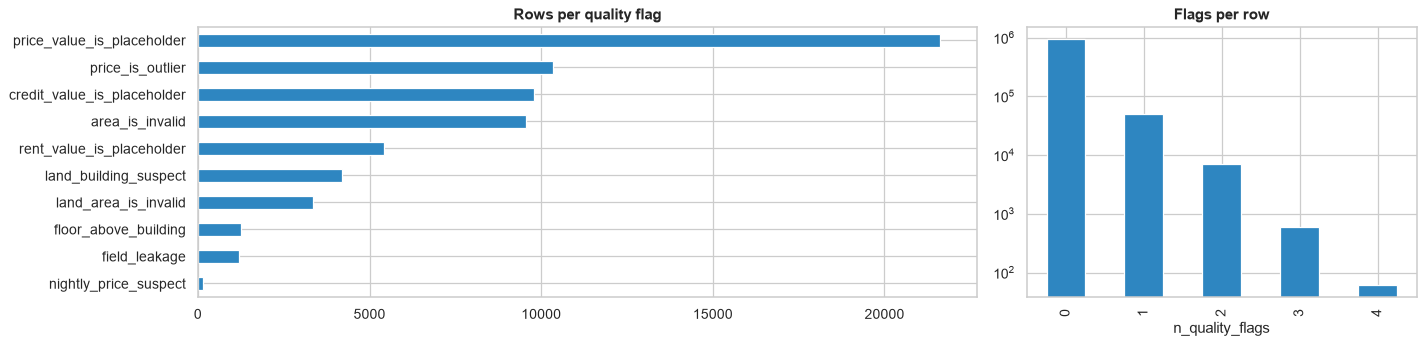

rows with no flag: 94.2%


In [ ]:
reg = df["rent_price_on_regular_days"]
floor, total = df["floor"].astype("Float64"), df["total_floors_count"].astype("Float64")
df["land_building_suspect"] = (df["land_area"] / df["area"]).lt(0.5)  # plot < half the floor area: swapped?
df["floor_above_building"] = (floor > total).fillna(False).astype(bool)
df["is_basement"] = floor.eq(-1).fillna(False).astype(bool)
df["nightly_price_suspect"] = (df["rent_price_at_weekends"].lt(reg) | df["rent_price_on_special_days"].lt(reg))
fam = df["deal_family"]
df["field_leakage"] = ((fam.ne("sell") & df["price_value"].notna()) | (fam.ne("long_rent") & df["credit_value"].notna())
                       | (fam.ne("temp_rent") & reg.notna())).fillna(False)
QUALITY_FLAGS = ["area_is_invalid", "land_area_is_invalid", "land_building_suspect", "floor_above_building",
                 "nightly_price_suspect", "field_leakage", "price_is_outlier", "price_value_is_placeholder",
                 "credit_value_is_placeholder", "rent_value_is_placeholder"]
df["n_quality_flags"] = df[QUALITY_FLAGS].fillna(False).astype("int8").sum(axis=1).astype("int8")

fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [2, 1]})
df[QUALITY_FLAGS].sum().sort_values().plot.barh(ax=axes[0], color="#2e86c1", title="Rows per quality flag")
df["n_quality_flags"].value_counts().sort_index().plot.bar(ax=axes[1], logy=True, color="#2e86c1", title="Flags per row")
plt.tight_layout(); plt.show()
print(f"rows with no flag: {df['n_quality_flags'].eq(0).mean():.1%}")

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">۹۴.۲٪ ردیف‌ها هیچ flag ندارند و فقط چند صد ردیف سه flag یا بیشتر دارند، پس مشکلات پراکنده‌اند. تعداد flagهای هر ردیف در ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">n_quality_flags</code>⁩ ذخیره شده تا هر تحلیل خودش تصمیم بگیرد چقدر سخت‌گیر باشد.</p>
</div>

## 6. Geography

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">pinهایی که بیرون از محدوده‌ی ایران افتاده‌اند قطعاً اشتباه‌اند و NA می‌شوند. ولی pinی که از شهر اعلام‌شده دور است لزوماً اشتباه نیست (شهرهای اقماری، شهرستان‌های بزرگ)، پس فقط flag می‌شود. مرکز هر شهر را median مختصات pinهای همان شهر گرفتیم. percentileهای فاصله تا مرکز شهر:</p>
</div>

In [ ]:
assert "geo_outside_iran" not in df, "run the notebook from the top"
lat, lon = df["location_latitude"], df["location_longitude"]
outside = (lat.notna() | lon.notna()) & ~(lat.between(24.5, 40.0) & lon.between(43.5, 63.5))  # Iran's bounding box
df["geo_outside_iran"] = outside.fillna(False)
df["location_latitude"], df["location_longitude"] = lat.mask(outside), lon.mask(outside)
print("pins outside Iran (nulled):", int(outside.sum()))

def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2, dl = np.radians(lat1), np.radians(lat2), np.radians(lon2 - lon1)
    h = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))

city = df["city_slug"].astype("string")
g = df.groupby(city, observed=True)
enough = g["location_latitude"].transform("count") >= 30
centre_lat = g["location_latitude"].transform("median").where(enough)
centre_lon = g["location_longitude"].transform("median").where(enough)
df["distance_to_city_km"] = haversine_km(df["location_latitude"], df["location_longitude"], centre_lat, centre_lon)
df["distance_to_city_km"].quantile([.5, .9, .95, .99, .999]).round(1).to_dict()

pins outside Iran (nulled): 23


{0.5: 4.4, 0.9: 14.1, 0.95: 21.5, 0.99: 69.1, 0.999: 403.5}

In [ ]:
df["geo_far_from_city"] = df["distance_to_city_km"].gt(60).fillna(False)  # flag only: satellite towns are real
print("far from own city (flagged):", int(df["geo_far_from_city"].sum()))

def to_utm(lat_deg, lon_deg, zone=39, a=6378137.0, f=1 / 298.257223563, k0=0.9996):
    """WGS84 -> UTM metres in one fixed zone (Snyder's series), so the whole country is one flat plane."""
    e2 = f * (2 - f); ep2 = e2 / (1 - e2)
    lat, lon = np.radians(lat_deg), np.radians(lon_deg)
    n = a / np.sqrt(1 - e2 * np.sin(lat) ** 2)
    t, c, A = np.tan(lat) ** 2, ep2 * np.cos(lat) ** 2, (lon - np.radians(zone * 6 - 183)) * np.cos(lat)
    m = a * ((1 - e2 / 4 - 3 * e2**2 / 64 - 5 * e2**3 / 256) * lat - (3 * e2 / 8 + 3 * e2**2 / 32 + 45 * e2**3 / 1024)
             * np.sin(2 * lat) + (15 * e2**2 / 256 + 45 * e2**3 / 1024) * np.sin(4 * lat) - 35 * e2**3 / 3072 * np.sin(6 * lat))
    x = k0 * n * (A + (1 - t + c) * A**3 / 6 + (5 - 18 * t + t**2 + 72 * c - 58 * ep2) * A**5 / 120) + 500_000
    y = k0 * (m + n * np.tan(lat) * (A**2 / 2 + (5 - t + 9 * c + 4 * c**2) * A**4 / 24
                                     + (61 - 58 * t + t**2 + 600 * c - 330 * ep2) * A**6 / 720))
    return x, y

# test: UTM distance vs great-circle distance for random pairs of pins in the same city
pins = df.loc[df["location_latitude"].notna() & ~df["geo_far_from_city"], ["city_slug", "location_latitude", "location_longitude"]]
first = pins.sample(20_000, random_state=0)
second = pins[pins["city_slug"].isin(first["city_slug"])].groupby("city_slug", observed=True).sample(1, random_state=1)
pair = first.merge(second, on="city_slug", suffixes=("", "_b"))
xa, ya = to_utm(pair["location_latitude"], pair["location_longitude"]); xb, yb = to_utm(pair["location_latitude_b"], pair["location_longitude_b"])
hv = haversine_km(pair["location_latitude"], pair["location_longitude"], pair["location_latitude_b"], pair["location_longitude_b"])
err = (np.hypot(xa - xb, ya - yb) / 1000 / hv - 1).where(hv > 1)
print(f"UTM vs haversine, same-city pairs > 1 km: median |error| {err.abs().median():.2%}, max {err.abs().max():.2%}")

far from own city (flagged): 7739
UTM vs haversine, same-city pairs > 1 km: median |error| 0.17%, max 1.70%


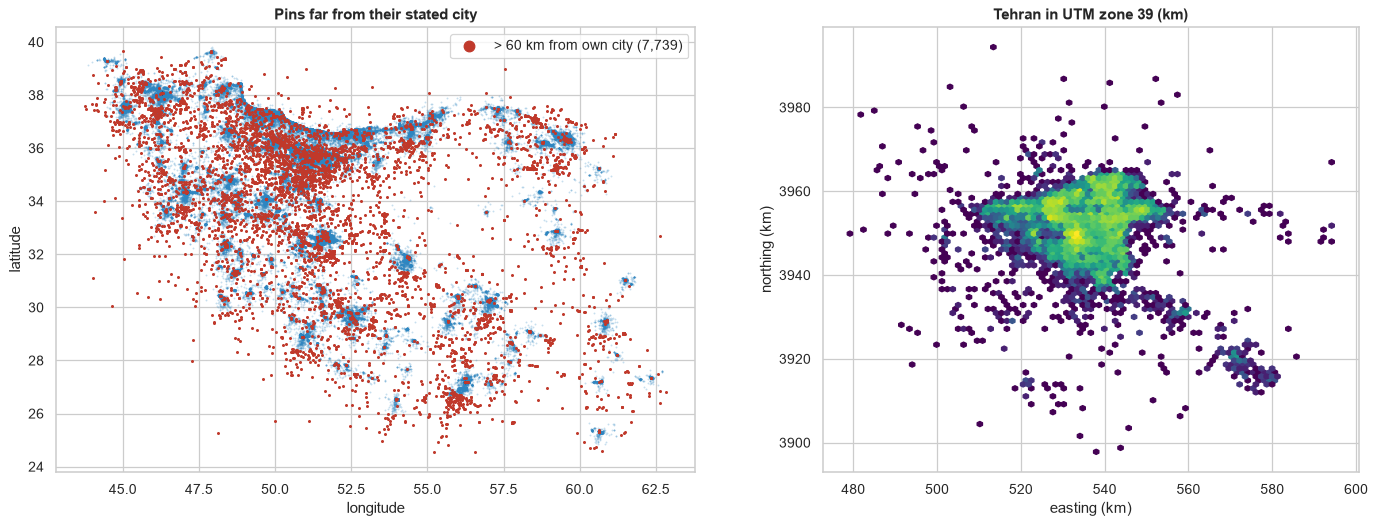

In [ ]:
df["utm_x"], df["utm_y"] = to_utm(df["location_latitude"], df["location_longitude"])
df["utm_zone"] = 39
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
geo, far = df.dropna(subset=["location_latitude"]), df["geo_far_from_city"]
axes[0].scatter(geo.loc[~far, "location_longitude"], geo.loc[~far, "location_latitude"], s=.2, alpha=.3, color="#2e86c1")
axes[0].scatter(df.loc[far, "location_longitude"], df.loc[far, "location_latitude"], s=2, color="#c0392b", label=f"> 60 km from own city ({int(far.sum()):,})")
axes[0].legend(markerscale=6); axes[0].set(title="Pins far from their stated city", xlabel="longitude", ylabel="latitude")
th = df[df["city_slug"].eq("tehran") & df["utm_x"].notna() & ~far]
axes[1].hexbin(th["utm_x"] / 1000, th["utm_y"] / 1000, gridsize=90, bins="log", cmap="viridis", mincnt=1)
axes[1].set(title="Tehran in UTM zone 39 (km)", xlabel="easting (km)", ylabel="northing (km)", aspect="equal")
plt.tight_layout(); plt.show()

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">۲۳ pin بیرون از ایران بودند و ۷٬۷۳۹ pin بیش از ۶۰ کیلومتر با مرکز شهرشان فاصله دارند. ۶۰ کیلومتر را نزدیک p99 (۶۹ کیلومتر) انتخاب کردیم.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">برای clustering همه‌ی نقاط را به UTM با zone ثابت ۳۹ بردیم. ایران بین zoneهای ۳۸ تا ۴۱ است و اگر هر نقطه با zone خودش تبدیل شود مختصات پیوسته نمی‌ماند و K-means و DBSCAN فاصله‌ها را اشتباه می‌بینند. طبق test بالا، اختلاف فاصله‌ی UTM با فاصله‌ی واقعی روی کره برای نقطه‌های داخل یک شهر به طور median ۰.۱۷٪ است. بیشترین اختلاف ۱.۷٪ است و مربوط به شهرهای شرقی که از مرکز zone دورند.</p>
</div>

## 7. Duplicates and city class

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">duplicateها را با دو معیار پیدا می‌کنیم: یکی بودن مشخصات اصلی (دسته، شهر، محله، متراژ، مبلغ، مختصات و ماه) یا یکی بودن متن توضیحات. نسخه‌ی اول نگه داشته می‌شود و بقیه flag می‌شوند. بعد label کلان‌شهر یا شهر کوچک را از فهرستی که در داکیومنتیشن پروژه آمده اضافه می‌کنیم.</p>
</div>

In [ ]:
DUP_KEYS = ["cat3_slug", "city_slug", "neighborhood_slug", "area", "price_value", "credit_value", "rent_value",
            "location_latitude", "location_longitude", "created_at_month"]
df["is_duplicate_key"] = df.duplicated(DUP_KEYS)
digest, present = [], []  # the description is ~700 MB: only its hash is kept
for chunk in pd.read_csv("../data/Divar.csv", usecols=["description"], chunksize=100_000):
    digest.append(pd.util.hash_pandas_object(chunk["description"], index=False).to_numpy())
    present.append(chunk["description"].notna().to_numpy())
df["is_duplicate_text"] = pd.Series(np.concatenate(digest), index=df.index).duplicated() & np.concatenate(present)
df["is_duplicate"] = df["is_duplicate_key"] | df["is_duplicate_text"]
print({c: int(df[c].sum()) for c in ["is_duplicate_key", "is_duplicate_text", "is_duplicate"]},
      "| both:", int((df["is_duplicate_key"] & df["is_duplicate_text"]).sum()))

{'is_duplicate_key': 14079, 'is_duplicate_text': 10551, 'is_duplicate': 23976} | both: 654


In [ ]:
ref = pd.read_csv("../data/iran_city_classification.csv")
ref.columns = ["city_slug", "city_class"]
print(ref["city_class"].value_counts().to_dict(),
      f"| cities covered: {df['city_slug'].isin(ref['city_slug']).groupby(df['city_slug'], observed=True).first().mean():.0%}",
      f"| ads covered: {df['city_slug'].isin(ref['city_slug']).mean():.0%}")
labels = df["city_slug"].astype("string").map(
    ref.set_index("city_slug")["city_class"].str.strip().replace({"کلان‌شهر": "metro", "شهر کوچک": "small_city"}))
df["city_class_imputed"] = labels.isna()
df["city_class"] = labels.fillna("small_city").astype("category")  # cities missing from the list are all small towns
print(df["city_class"].value_counts().to_dict())

{'شهر کوچک': 231, 'کلان\u200cشهر': 9} | cities covered: 57% | ads covered: 96%
{'small_city': 535201, 'metro': 464799}


<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">۱۴٬۰۷۹ آگهی با معیار مشخصات و ۱۰٬۵۵۱ با معیار متن تکراری‌اند و فقط ۶۵۴ آگهی در هر دو مشترک‌اند؛ پس هر دو معیار لازم بودند. در مجموع ۲۳٬۹۷۶ ردیف.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">فهرست شهرهای داکیومنتیشن ۵۷٪ شهرها ولی ۹۶٪ آگهی‌ها را پوشش می‌دهد. شهرهایی که در آن نیستند همه کوچک‌اند، پس label «شهر کوچک» گرفتند و ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">city_class_imputed</code>⁩ مشخصشان می‌کند. یک نکته را باید در نظر داشت: پرند، اندیشه و پردیس در این فهرست «شهر کوچک»اند در حالی که عملاً بخشی از منطقه‌ی تهران‌اند.</p>
</div>

## 8. Amenity summary

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">برای آزمون فرض‌ها تعداد امکانات لوکس (استخر، جکوزی، سونا، باربیکیو) و امکانات پایه‌ی هر آگهی را می‌شماریم. اگر NA را «ندارد» حساب کنیم، هر آپارتمانی «ویلای بدون استخر» می‌شود؛ برای همین شمارش فقط برای آگهی‌هایی انجام می‌شود که حداقل به یکی از fieldهای آن گروه جواب داده‌اند.</p>
</div>

In [ ]:
LUXURY = ["has_pool", "has_jacuzzi", "has_sauna", "has_barbecue"]
BASIC = ["has_elevator", "has_parking", "has_warehouse", "has_balcony", "has_security_guard",
         "has_warm_water_provider", "has_heating_system", "has_cooling_system", "has_restroom"]
for group, prefix in ((LUXURY, "luxury"), (BASIC, "basic")):
    # categorical amenities (heating type ...) have no "no" option: filled = present, empty = unknown
    frame = pd.DataFrame({c: df[c] if df[c].dtype == "boolean" else df[c].notna().where(df[c].notna()).astype("boolean")
                          for c in group})
    answered, count = frame.notna().any(axis=1), frame.sum(axis=1, min_count=1)
    df[f"{prefix}_amenity_count"] = count.where(answered).astype("Int8")
    df[f"has_{prefix}_amenity"] = count.gt(0).where(answered).astype("boolean")
    df[f"{prefix}_amenity_asked"] = answered
print({g: f"{df[f'{g}_amenity_asked'].mean():.1%}" for g in ["luxury", "basic"]})
df.groupby("cat3_slug", observed=True)["luxury_amenity_asked"].mean().loc[lambda s: s > 0].round(3)

{'luxury': '3.2%', 'basic': '73.2%'}


cat3_slug
apartment-sell      0.000
house-villa-rent    0.079
house-villa-sell    0.182
villa               0.330
Name: luxury_amenity_asked, dtype: float64

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">فقط ۳.۲٪ آگهی‌ها به سؤال امکانات لوکس جواب داده‌اند و همه‌شان ویلایی‌اند. ولی حتی بین ویلایی‌ها هم فقط ۸ تا ۳۳ درصد جواب داده‌اند؛ یعنی فرم سؤال را پرسیده و آگهی‌دهنده جواب نداده. در بخش بعد سعی می‌کنیم این جاهای خالی را از روی متن آگهی پر کنیم.</p>
</div>

## 9. Amenities from the description

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">خیلی از آگهی‌دهنده‌ها امکانات را در فرم تیک نزده‌اند ولی در توضیحات نوشته‌اند. روی آگهی‌هایی که فرمشان پر است یک Logistic Regression را train می‌کنیم که از روی کلمات متن (TF-IDF روی unigram و bigram) حدس بزند آگهی آن امکان را دارد یا نه. هیچ فهرست کلمه‌ای دستی وارد نشده و مدل وزن کلمات را خودش از داده یاد می‌گیرد.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">ستون اصلی فرم تغییر نمی‌کند و نتیجه در ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">*_filled</code>⁩، ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">*_prob</code>⁩ و ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">*_source</code>⁩ ذخیره می‌شود. پیش‌بینی هم فقط برای دسته‌های ویلایی انجام می‌شود، چون مدل فقط متن ویلاها را دیده است.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">قبل از ساخت ماتریس متن را کمی مرتب می‌کنیم: ي و ك عربی را فارسی می‌کنیم، نیم‌فاصله را فاصله می‌کنیم و هر کلمه‌ای که عدد دارد (قیمت، شماره تلفن، کد آگهی) را کنار می‌گذاریم. bigramها لازم‌اند تا مدل «بدون استخر» را از «استخر» تشخیص بدهد.</p>
</div>

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

VILLA_CATS = ["house-villa-sell", "house-villa-rent", "villa"]
villa = df["cat3_slug"].isin(VILLA_CATS)
pd.DataFrame({"filled, all ads": df[LUXURY].notna().mean(), "filled, villa ads": df.loc[villa, LUXURY].notna().mean(),
              "yes rate where filled": df.loc[villa, LUXURY].astype(float).mean()}).round(3)

,"filled, all ads","filled, villa ads",yes rate where filled
has_pool,0.029,0.147,0.127
has_jacuzzi,0.029,0.144,0.079
has_sauna,0.028,0.143,0.049
has_barbecue,0.031,0.157,0.251


In [ ]:
CHAR_MAP = str.maketrans({"ي": "ی", "ك": "ک", "\u200c": " "})
DIGIT_TOKEN = re.compile(r"\S*[\d۰-۹٠-٩]\S*")  # prices, areas, phone numbers, agency ad codes
keep, parts, start = villa.to_numpy(), [], 0
for chunk in pd.read_csv("../data/Divar.csv", usecols=["title", "description"], chunksize=200_000):
    rows = keep[start:start + len(chunk)]
    t = (chunk["title"].fillna("") + " " + chunk["description"].fillna("")).to_numpy()[rows]
    parts.append(pd.Series(t, index=np.arange(start, start + len(chunk))[rows]))
    start += len(chunk)
text = pd.concat(parts).map(lambda s: DIGIT_TOKEN.sub(" ", s.translate(CHAR_MAP)))

vec = TfidfVectorizer(min_df=20, ngram_range=(1, 2), sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
X = vec.fit_transform(text)
terms, row_of = vec.get_feature_names_out(), pd.Series(np.arange(len(text)), index=text.index)
print(f"{len(text):,} villa texts | median {text.str.split().str.len().median():.0f} words | TF-IDF {X.shape[1]:,} terms")
text.head(2).str[:110]

199,330 villa texts | median 40 words | TF-IDF 60,677 terms


0     باغ ویلا اجاره روزانه استخر داخل لشکرآباد سهیل...
20    ویلای خوش نقشه ویلایی چهار خواب\nحیاط پایین و ...
dtype: str

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">دو نکته درباره‌ی train مدل:</p>
<ul dir="rtl" style="direction:rtl; text-align:right; padding-right:2.4em; padding-left:0;">
<li dir="rtl" style="text-align:right;">برای ارزیابی، آگهی‌های هر شهر یا همه در train هستند یا همه در test (⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">GroupKFold</code>⁩). یک آژانس املاک معمولاً در یک شهر ده‌ها آگهی با متن مشابه می‌گذارد و تیک‌ها را هم یکسان می‌زند. اگر این آگهی‌ها هم در train باشند و هم در test، مدل اسم آژانس را حفظ می‌کند و scoreاش بهتر از واقعیت درمی‌آید.</li>
<li dir="rtl" style="text-align:right;">threshold تصمیم را ۰.۵ نگذاشتیم. سونا فقط در ۵٪ آگهی‌ها هست و با threshold ۰.۵ تقریباً هیچ‌وقت پیش‌بینی نمی‌شود. thresholdی را برداشتیم که F1 را بیشینه کند، و برای اینکه score گزارش‌شده خوش‌بینانه نباشد threshold هر fold فقط از داده‌ی train همان fold انتخاب شده است.</li>
</ul>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">اول روی استخر امتحانش می‌کنیم:</p>
</div>

In [ ]:
def best_threshold(y, p):
    precision, recall, thr = precision_recall_curve(y, p)
    return thr[np.argmax(2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12))]

def oof_proba(X, y, groups, n_splits, C=4.0):
    p = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits).split(X, y, groups):
        p[te] = LogisticRegression(C=C, max_iter=2000).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    return p

def fit_amenity(col, C=4.0):
    """Train on ads whose form answered `col`; score with whole cities held out."""
    lab = df.loc[text.index, col].notna() & ~df.loc[text.index, "is_duplicate"]
    idx = lab[lab].index
    Xl, y, groups = X[row_of[idx].to_numpy()], df.loc[idx, col].astype(int).to_numpy(), df.loc[idx, "city_slug"].astype(str).to_numpy()
    p_out, hit = np.zeros(len(y)), np.zeros(len(y), bool)
    for tr, te in GroupKFold(5).split(Xl, y, groups):  # threshold of each fold tuned on its training part only
        thr = best_threshold(y[tr], oof_proba(Xl[tr], y[tr], groups[tr], 3, C))
        p_out[te] = LogisticRegression(C=C, max_iter=2000).fit(Xl[tr], y[tr]).predict_proba(Xl[te])[:, 1]
        hit[te] = p_out[te] >= thr
    precision, recall, f1, _ = precision_recall_fscore_support(y, hit, average="binary")
    model = LogisticRegression(C=C, max_iter=2000).fit(Xl, y)
    return {"model": model, "threshold": best_threshold(y, p_out), "y": y, "p_out": p_out,
            "score": {"train ads": len(y), "yes rate": y.mean(), "AUC": roc_auc_score(y, p_out),
                      "precision": precision, "recall": recall, "F1": f1},
            "terms": pd.Series(model.coef_[0], index=terms)}

pool = fit_amenity("has_pool")
print({k: round(float(v), 3) for k, v in pool["score"].items()}, "| threshold", round(float(pool["threshold"]), 3))
pd.DataFrame({"towards YES": pool["terms"].nlargest(10).index, "towards NO": list(pool["terms"].nsmallest(6).index) + [""] * 4})

{'train ads': 28198.0, 'yes rate': 0.124, 'AUC': 0.929, 'precision': 0.599, 'recall': 0.746, 'F1': 0.665} | threshold 0.223


,towards YES,towards NO
0,استخر,خانه
1,استخردار,ویلایی
2,استخرداخلی,برای اطلاعات
3,فرهادی,منزل
4,ویلااستخردار,شهرک برند
5,کداگهی,سهیلیه
6,تریبلکس,
7,دارای استخر,
8,جکوزی,
9,خانم فرهادی,


In [ ]:
fits = {"has_pool": pool} | {c: fit_amenity(c) for c in LUXURY[1:]}
report = pd.DataFrame({c: f["score"] | {"threshold": f["threshold"]} for c, f in fits.items()}).T.astype(float).round(3)
display(report)
pd.DataFrame({c: list(f["terms"].nlargest(6).index) for c, f in fits.items()})

,train ads,yes rate,AUC,precision,recall,F1,threshold
has_pool,28198.0,0.124,0.929,0.599,0.746,0.665,0.223
has_jacuzzi,27608.0,0.078,0.916,0.544,0.641,0.589,0.200
has_sauna,27376.0,0.048,0.923,0.486,0.546,0.515,0.203
has_barbecue,29901.0,0.248,0.855,0.537,0.722,0.616,0.329


,has_pool,has_jacuzzi,has_sauna,has_barbecue
0,استخر,جکوزی,سونا,باربیکیو
1,استخردار,فرهادی,فرهادی,جکوزی
2,استخرداخلی,استخر,استخر,فرهادی
3,فرهادی,کداگهی,جکوزی,استخر
4,ویلااستخردار,تریبلکس,خانم فرهادی,کداگهی
5,کداگهی,خانم فرهادی,کداگهی,کد


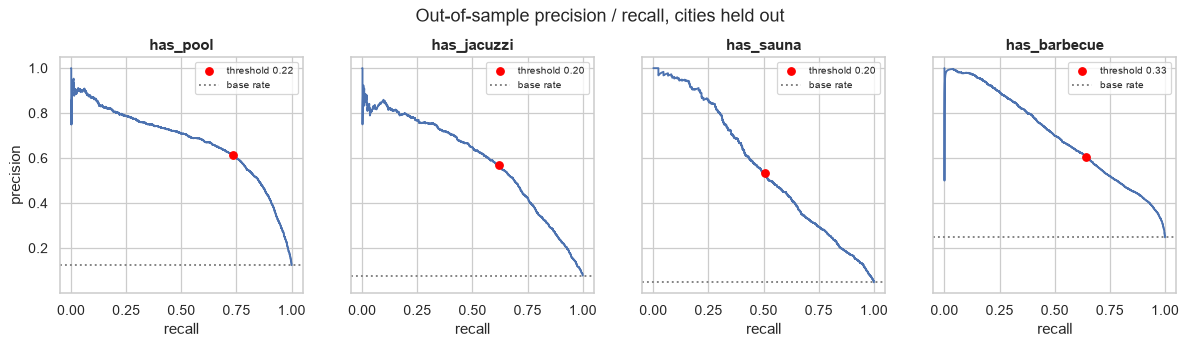

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, (c, f) in zip(axes, fits.items()):
    precision, recall, thr = precision_recall_curve(f["y"], f["p_out"])
    i = np.argmin(np.abs(thr - f["threshold"]))
    ax.plot(recall, precision); ax.scatter(recall[i], precision[i], color="red", zorder=3, label=f"threshold {f['threshold']:.2f}")
    ax.axhline(f["y"].mean(), ls=":", color="grey", label="base rate"); ax.set(title=c, xlabel="recall"); ax.legend(fontsize=8)
axes[0].set_ylabel("precision"); plt.suptitle("Out-of-sample precision / recall, cities held out", y=1.04); plt.show()

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">F1 از ۰.۵۲ برای سونا تا ۰.۶۷ برای استخر است و thresholdها بین ۰.۲۰ و ۰.۲۹. این عددها خیلی بالا نیستند، ولی بخش زیادی از خطا به خود labelها برمی‌گردد: خیلی‌ها امکانی را که دارند در فرم تیک نمی‌زنند.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">در هر چهار مدل مهم‌ترین کلمه اسم خود امکان است و مدل شکل‌های دیگرش را هم پیدا کرده (استخردار، استخرداخلی، «دارای استخر»). بعد از آن کلمات امکانات دیگر آمده‌اند، مثلاً برای سونا «استخر» و «جکوزی»؛ یعنی بخشی از پیش‌بینی از لوکس بودن کلی ویلا می‌آید. برای مدل قیمت این مشکلی ندارد، ولی در آزمون فرض‌ها ستون‌های فرم را مبنا می‌گذاریم و از این ستون‌ها فقط برای sensitivity analysis استفاده می‌کنیم. بین این چهار، ستون استخر از سونا و باربیکیو قابل‌اعتمادتر است.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">بین کلمات مهم اسم یکی دو مشاور املاک هم دیده می‌شود. حذف اعداد شماره تلفن‌ها را برد ولی اسم‌ها ماندند. چون score روی شهرهای کنارگذاشته حساب شده، اثر این موضوع در عددهای بالا لحاظ شده است.</p>
</div>

In [ ]:
before_lux = df[LUXURY].copy()
for c, f in fits.items():
    rows = df.loc[text.index, c].isna().loc[lambda s: s].index  # villa ads whose form is empty
    prob = pd.Series(np.nan, index=df.index)
    prob[rows] = f["model"].predict_proba(X[row_of[rows].to_numpy()])[:, 1]
    df[f"{c}_prob"] = prob
    df[f"{c}_filled"] = df[c].astype("boolean").mask(prob.notna(), prob >= f["threshold"])
    df[f"{c}_source"] = pd.Categorical(np.where(df[c].notna(), "form", np.where(prob.notna(), "model", None)))
filled = df[[f"{c}_filled" for c in LUXURY]]
df["luxury_amenity_count_filled"] = filled.sum(axis=1, min_count=1).astype("Int8")
df["has_luxury_amenity_filled"] = filled.any(axis=1).where(filled.notna().any(axis=1)).astype("boolean")
assert df[LUXURY].equals(before_lux), "the form columns must stay untouched"

pd.DataFrame({c: {"form": df[f"{c}_source"].eq("form").sum(), "model": df[f"{c}_source"].eq("model").sum(),
                  "yes rate, form": df.loc[df[f"{c}_source"].eq("form"), f"{c}_filled"].astype(float).mean(),
                  "yes rate, model": df.loc[df[f"{c}_source"].eq("model"), f"{c}_filled"].astype(float).mean(),
                  "model rows outside villas": (df[f"{c}_source"].eq("model") & ~villa).sum()} for c in LUXURY}).T.round(3)

,form,model,"yes rate, form","yes rate, model",model rows outside villas
has_pool,29390.0,169941.0,0.127,0.047,0.0
has_jacuzzi,28728.0,170603.0,0.079,0.028,0.0
has_sauna,28479.0,170852.0,0.049,0.016,0.0
has_barbecue,31198.0,168133.0,0.251,0.059,0.0


ads with >= 1 luxury amenity: form 8,646 -> form + text 21,262


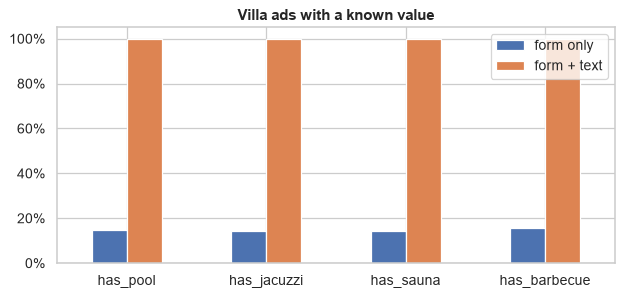

In [ ]:
print(f"ads with >= 1 luxury amenity: form {int(df['has_luxury_amenity'].sum()):,} -> form + text {int(df['has_luxury_amenity_filled'].sum()):,}")
cov = pd.DataFrame({"form only": df.loc[villa, LUXURY].notna().mean().values,
                    "form + text": df.loc[villa, [f"{c}_filled" for c in LUXURY]].notna().mean().values}, index=LUXURY)
ax = cov.plot.bar(figsize=(8, 3.4), rot=0, title="Villa ads with a known value")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); plt.show()
del text, X

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">حدود ۱۷۰ هزار آگهی ویلایی از مدل مقدار گرفتند، هیچ پیش‌بینی بیرون از ویلایی‌ها انجام نشد و ستون‌های فرم تغییری نکردند.</p>
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">نرخ «دارد» در ردیف‌هایی که مدل پر کرده خیلی کمتر از ردیف‌های فرم است (برای استخر ۴.۸٪ در مقابل ۱۲.۷٪). دو دلیل می‌تواند داشته باشد که با این داده نمی‌شود از هم جدایشان کرد: یا کسانی که امکانات دارند بیشتر فرم را پر می‌کنند، یا امکانی که در متن نیامده برای مدل دیده نمی‌شود. پس «ندارد» از مدل را باید «در متن اشاره‌ای نشده» خواند.</p>
</div>

## 10. Summary

<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">جدول زیر برای ستون‌هایی که تغییر کرده‌اند نوع و درصد missing value را قبل و بعد از پیش‌پردازش نشان می‌دهد. ⁦<code dir="ltr" style="direction:ltr; unicode-bidi:isolate;">category</code>⁩ در ستون «قبل» یعنی متن خام.</p>
</div>

In [ ]:
report = pd.DataFrame({"dtype before": raw.dtypes.astype(str), "dtype after": df.dtypes.astype(str),
                       "missing before": raw.isna().mean(), "missing after": df.isna().mean()})
report["status"] = np.select([report["dtype before"].isna(), report["dtype after"].isna()], ["new", "dropped"], "kept")
report["missing change"] = report["missing after"] - report["missing before"]
print(report["status"].value_counts().to_dict(), "| dropped:", report.index[report["status"].eq("dropped")].tolist())
kept = report[report["status"].eq("kept")]
kept.loc[kept["dtype before"].ne(kept["dtype after"]) | kept["missing change"].abs().gt(0.0005)].sort_values("missing change", ascending=False).round(4)

{'new': 72, 'kept': 55, 'dropped': 3} | dropped: ['rent_to_single', 'transformable_credit', 'transformable_rent']


,dtype before,dtype after,missing before,missing after,status,missing change
price_value,float64,float64,0.4317,0.4533,kept,0.0216
credit_value,float64,float64,0.6479,0.6577,kept,0.0098
has_cooling_system,category,category,0.6494,0.6553,kept,0.0059
rent_value,float64,float64,0.6487,0.6541,kept,0.0054
building_direction,category,category,0.6761,0.6793,kept,0.0032
has_heating_system,category,category,0.6310,0.6341,kept,0.0031
floor_material,category,category,0.5940,0.5957,kept,0.0017
rent_price_on_regular_days,float64,float64,0.9819,0.9834,kept,0.0014
has_warm_water_provider,category,category,0.6205,0.6219,kept,0.0014
rent_price_at_weekends,float64,float64,0.9864,0.9876,kept,0.0012


In [ ]:
pd.DataFrame({"raw": [len(raw), raw.shape[1], raw["price_value"].notna().sum(), raw["building_size"].notna().sum(),
                      raw["location_latitude"].notna().sum(), np.nan, np.nan],
              "clean": [len(df), df.shape[1], df["target_price"].notna().sum(), df["area"].notna().sum(),
                        df["location_latitude"].notna().sum(), df["n_quality_flags"].gt(0).sum(), df["is_duplicate"].sum()]},
             index=["rows", "columns", "usable price", "usable area", "with coordinates", "flagged rows", "duplicates"]).astype("Int64")

,raw,clean
rows,1000000,1000000
columns,58,127
usable price,568346,902190
usable area,980394,970845
with coordinates,655608,655585
flagged rows,<NA>,58350
duplicates,<NA>,23976


<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">همه‌ی انتخاب‌هایی که در این نوت‌بوک بر اساس قضاوت خودمان بوده، همراه دلیلش. خروجی‌ای که هر کدام بر اساس آن گرفته شده در بخش مربوط آمده است.</p>
</div>

In [ ]:
pd.DataFrame([
    ("drop column", "filled < 0.1%", "only rent_to_single; nothing to learn from 19 values"),
    ("reference_year", 1403, "the data is a 1403 snapshot"),
    ("dense month", f"≥ {DENSE_MIN:,} ads", "edge months of the extraction window (month plot)"),
    ("area bounds", "per cat3", "wide around clean percentiles; physical cap where p99 is polluted (area table)"),
    ("repdigit", "≥ 3 repeated digits", "111111, 9999999: keyboard noise"),
    ("amount bounds", "e.g. sell 1e7–1e13 toman", "outside the bulk of the price histogram"),
    ("credit_per_rent", "1M credit = 30k rent", "project documentation (3% a month)"),
    ("unit-error window", "−3.5 … −2.5 (×1000)", "separate bump at −3 in the peer-ratio histogram"),
    ("min group size", MIN_GROUP, "median of a thinner group is not a reference"),
    ("price outlier", "|log10 ratio| > 1.3", "≈ 20× from the group median"),
    ("land/building swap", "plot < 0.5 × floor area", "flag only: multi-storey villas are real"),
    ("far from city", "> 60 km", "near the p99 of distance to the city centre; flag only"),
    ("UTM zone", 39, "one plane for the whole country; checked against haversine"),
    ("text threshold", "max F1, out-of-sample", "amenity prevalence 5–25%, so 0.5 would kill recall"),
], columns=["decision", "value", "why"])

,decision,value,why
0,drop column,filled < 0.1%,only rent_to_single; nothing to learn from 19 ...
1,reference_year,1403,the data is a 1403 snapshot
2,dense month,"≥ 5,000 ads",edge months of the extraction window (month plot)
3,area bounds,per cat3,wide around clean percentiles; physical cap wh...
4,repdigit,≥ 3 repeated digits,"111111, 9999999: keyboard noise"
5,amount bounds,e.g. sell 1e7–1e13 toman,outside the bulk of the price histogram
6,credit_per_rent,1M credit = 30k rent,project documentation (3% a month)
7,unit-error window,−3.5 … −2.5 (×1000),separate bump at −3 in the peer-ratio histogram
8,min group size,30,median of a thinner group is not a reference
9,price outlier,|log10 ratio| > 1.3,≈ 20× from the group median


<div dir="rtl" style="direction:rtl; text-align:right;">
<p dir="rtl" align="right" style="direction:rtl; text-align:right;">قبل از ذخیره چند چیزی را که همیشه باید درست باشند چک می‌کنیم. اگر بعداً مرحله‌ای تغییر کند و یکی از این‌ها به هم بخورد، نوت‌بوک همین‌جا متوقف می‌شود.</p>
</div>

In [ ]:
checks = {
    "no row dropped": len(df) == len(raw),
    "no corrected price is an outlier": df.loc[df["price_unit_corrected"], "price_is_outlier"].sum() == 0,
    "prices and areas positive": (df["target_price"].dropna() > 0).all() and (df["area"].dropna() > 0).all(),
    "areas inside their category bounds": (df["area"].isna() | df["area"].between(low, high)).all(),
    "amounts inside their bounds": all((df[c].isna() | df[c].between(lo, hi) | ((c == "rent_value") & df[c].eq(0))).all()
                                       for c, (lo, hi) in AMOUNT_BOUNDS.items()),
    "no symbolic rent left": not df["rent_value"].isin([100_000, 111_111]).any(),
    "every pin inside Iran": df["location_latitude"].dropna().between(24.5, 40).all(),
    "flag count = sum of flags": df["n_quality_flags"].eq(df[QUALITY_FLAGS].sum(axis=1)).all(),
    "no duplicate left after dropping flagged": not df.loc[~df["is_duplicate"]].duplicated(DUP_KEYS).any(),
    "form amenity columns untouched by the text model": "before_lux" not in globals() or df[LUXURY].equals(before_lux),
}
failed = [k for k, ok in checks.items() if not ok]
assert not failed, failed
print(f"all {len(checks)} checks passed")

all 10 checks passed


In [ ]:
df.to_parquet("divar_clean.parquet")
print(f"saved {df.shape} | {df.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory | total {time.time() - t0:.0f} s")

ArrowKeyError: No type extension with name arrow.py_extension_type found